# Solving Frozen Lake by Hand

## Setup

### Install

We'll need 3 libraries:
1. When OpenAI was actually more open, they developed `gym`, a library giving a unified framework for Reinforcement Learning experiments. Maintenance gradually decreased, but then it was taken over by the non-profit the Farama Foundation. The new package is called `gymnasium`:  
https://gymnasium.farama.org/  
We install it with the option `toy_text` as that gets us Frozen Lake, the environment we'll introduce RL with:  
https://gymnasium.farama.org/environments/toy_text/frozen_lake/
2. To get gameplay videos, we use the package `moviepy`:  
https://zulko.github.io/moviepy/
3. To get gameplay images, we use the package `pillow`:
https://python-pillow.org/

Installing this packages is part of the installation instructions. However, if you are missing any of them, run this line in a terminal, with your `mamba` environment active:
```bash
pip install "gymnasium[toy_text]" moviepy pillow
```

### Imports

1. Import `Callable` and `torch`.
1. By convention, import `gymnasium` as `gym`.
4. So that we can see gameplay videos, import `Image` from `IPython.display`.
4. In order to make gameplay videos, import `ImageSequenceClip` from `moviepy`.
3. Import the module `os` so that we can create the video dictionary and get the gif paths from Python.
4. So that we can see gameplay images, import `Image` from `PIL` as `PILImage`.
5. Import `Optional` from `typing`. This is type hint for an argument that can be `None` or some other type.
6. Import the function `get_seed` that you created in Notebook 0620.

In [1]:
from collections.abc import Callable
import gymnasium as gym
from IPython.display import Image
from moviepy import ImageSequenceClip
import os
from PIL import Image as PILImage
import torch
from typing import Optional

from util_0624 import get_seed

### Constants

Create a configuration dictionary with the following keys:
- `"discount"`: `float`  
    This is the constant we use to get discounted returns. Make it the default `0.99`.
- `"env_id"`: `str`  
    In the unified API of `gym`, every MDP, or *environment* has a unique identifier. We'll play Frozen Lake. You can see on its page:  
    https://gymnasium.farama.org/environments/toy_text/frozen_lake/  
    that its identifier is `"FrozenLake-v1"`.
- `"env_kwargs"`: `dict`  
    This dictionary stores extra settings in the environment. Set it to the following:
    - `"is_slippery"`: `bool`  
        This makes the transitions stochastic:  
        https://gymnasium.farama.org/environments/toy_text/frozen_lake/#is_slippy  
        Set this to `False` for now.
    - `"map_name"`: `str`  
        If given, a preloaded map will be used:  
        https://gymnasium.farama.org/environments/toy_text/frozen_lake/#arguments  
        Set this to `"4x4"` for now.
- `"gif_fps"`: `int`  
    The frames per second (FPS) to use when making gameplay gifs. I set this to `20`. Change it at will.
- `"seed"`: `int`  
    This is for reproducible experiments. Insert any integer.
- `"videos_dictionary"`: `str`
    The path to the directory to store videos at. I set this to `videos`. Change it at will.

In [2]:
config = {
    "discount": 0.99,
    "env_id": "FrozenLake-v1",
    "env_kwargs": {
        "is_slippery": False,
        "map_name": "4x4",
    },
    "gif_fps": 5,
    "seed": 0,
    "videos_directory": "videos",
}

Set the `torch` pseudo-random number generation seed to the value given in the configuration dictionary.

In [3]:
torch.manual_seed(config["seed"])

## Meet a `gym.Env`

### `make` an `Env`

`gym` environments are created by the `gym.make` function.
1. Its positional argument should be the environment ID.
2. In its keyword argument `render_mode`, you can specify whether to save gameplay pictures and if so, how. See here:  
https://gymnasium.farama.org/api/env/#gymnasium.Env.render  
Set this to `rgb_array`.
3. Give it the extra keyword arguments stored at `env_kwargs` in the configuration dictionary using the destructuring operator `**`.

We get a `gym.Env` object. Print its `observation_space` and `action_space` attributes.

In [4]:
env = gym.make(
    config["env_id"],
    render_mode="rgb_array",
    **config["env_kwargs"]
)
print(env.observation_space, env.action_space)

Discrete(16) Discrete(4)


As you can see, the observation and action spaces are `gym.spaces.Discrete` objects. They describe discrete sets with 16 and 4 elements, respectively. You can see the environment documentation for description:  
https://gymnasium.farama.org/environments/toy_text/frozen_lake/#action-space

You can get the size of a `Discrete` object at its `n` attribute. Do this for both the observation and the action space.

You can sample an action uniformly from the action space using its `sample` method. Before this, you can set the seed of this sampler with the `seed` method. Do the latter first using `get_seed`, then sample 10 actions.

In [5]:
print(
    env.observation_space.n, 
    env.action_space.n
)
env.action_space.seed(get_seed())
print([env.action_space.sample() for _ in range(10)])

16 4
[np.int64(3), np.int64(2), np.int64(3), np.int64(2), np.int64(0), np.int64(0), np.int64(0), np.int64(2), np.int64(1), np.int64(1)]


### `reset`

You can reset an `Env` and thus get an initial observation by the `reset` method. For probabilistic environments, you can set the seed by the `seed` keyword argument. This time, as now transitions are deterministic, there is no need for setting the seed, but let's just as well do it, so that we don't forget about it, when we actually need it.

Print the output of the `reset` method.

In [6]:
print(env.reset(seed=get_seed()))

(0, {'prob': 1})


You received a pair of an initial observation and a metadata dictionary. In the latter, you can see the effect of the `is_slippery=False` setting: The character will move in the direction specified by the action with probability 1.

As we set `render_mode="rgb_array"`, the `render` method of the environment returns the picture of the initial observation as an RGB array. Feed this to `PILImage.fromarray` so that you can see the image in the notebook.

/home/pal-zsamboki/miniforge3/envs/dml/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


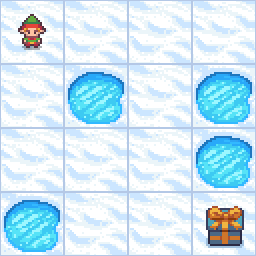

In [7]:
frame = env.render()
PILImage.fromarray(frame)

### `step`

We can take an action and receive the transition information by the `step` method of the environment. It returns a quintuple of:
1. the next observation,
2. the reward,
3. whether the environment was truncated by a maximum number of steps setting (does not apply right now)
4. whether the observation we received is that of a terminal state and
5. a dictionary of additional information.

Conferring the environment page, take a step to the right. Print the output of the `step` method. Then show the picture of the next observation.

In [ ]:
print(env.step(2))
PILImage.fromarray(env.render())

It's walking!

## Episodes

### Using a Random Policy

Time to generate an episode with a random policy!

1. At initialization:
    1. Create a return variable. Note that `return` is a Python reserved word, so you need to give the variable some other name.
    2. Create a list to store observation pictures in.
    3. Create a time step counter. Initialize it to 0.
    3. Reset the environment.
    4. Append to the picture list that of the initial observation.
    5. To make sure that the video dictionary exists, call `os.makedirs`. Use the `exist_ok` keyword argument so that it does not throw an error if the dictionary exists already.
2. In an infinite loop:
    1. Sample an action.
    2. Take a step with the action. Get the reward and the termination information.
    3. Update the return using:
        1. the reward,
        2. the discount, as given in the configuration dictionary and
        3. the time step counter.
    4. Append to the picture list that of the last observation.
    5. If this is a terminal state, break the loop.
    6. Increment the step counter.
3. Print the return.
4. To get a gameplay gif and show it, use these instructions:  
    https://stackoverflow.com/questions/60914488/how-can-i-make-gif-using-arrays/64796174#64796174  
    You can get a gif path by concatenating the video directory path and a file name using `os.path.join`.

In [ ]:
episode_return = 0
frames = []
step_id = 0
env.reset(seed=get_seed())
frames.append(env.render())
os.makedirs(config["videos_directory"], exist_ok=True)
while True:
    action = env.action_space.sample()
    _, reward, terminated, _,  _ = env.step(action)
    episode_return += reward * config["discount"] ** step_id
    frames.append(env.render())
    if terminated:
        break

    step_id += 1

print(f"Episode return: {episode_return}")

# https://stackoverflow.com/a/64796174
clip = ImageSequenceClip(frames, fps=config["gif_fps"])
gif_path = os.path.join(config["videos_directory"], "test.gif")
clip.write_gif(gif_path, fps=config["gif_fps"])

Image(gif_path)

### Solving the Environment by Hand

Time to write a deterministic policy that solves this environment! You can make it a list of 16 action indices. Then as observations are state indices, indexing into it by an observation index, you should get an action.

Also, refactor your above episode runner into a function that has a policy argument. The policy should be a function that takes an observation and returns an action. If the policy is set at its default value `None`, inside the function, create a random policy function. Note that we also make movie generation optional.

Finally before you test your solution, calculate the discounted return by hand. You can see on the environment page that you get reward 1 if you reach the gift box and 0 otherwise. Then see if you indeed got that discounted return in the episode.

In [ ]:
def run_episode(
    config: dict,
    env: gym.Env,
    gif_name: Optional[str] = None,
    policy: Optional[Callable[[int], int]]=None,
) -> float:
    """
    Run an episode in a `gym.Env`
    with discrete observation and action spaces,
    following a policy.

    Make a gif video of the gameplay.

    Parameters
    ----------
    config : dict
        Configuration dictionary. Required key-value pairs:
        gif_fps : int
            Frames per second in the gif.
        video_directory : str
            If `gif_name` is given, the created movie will be saved
            to this directory.
    env : gym.Env
        The environment to get an episode in.
    gif_name : str, optional
        If given, a gif movie is saved to this filename
        in `config['videos_directory]`.
    policy : Callable[[int], int], optional
        The policy to get an episode with. Default: random policy.

    Returns
    -------
    The discounted return of the episode.
    """
    if policy is None:
        policy = lambda observation: env.action_space.sample()

    episode_return = 0
    frames = []
    step_id = 0
    observation, _ = env.reset(seed=get_seed())
    if gif_name is not None:
        os.makedirs(config["videos_directory"], exist_ok=True)
        frames.append(env.render())

    while True:
        action = policy(observation)
        observation, reward, _, terminated, _ = env.step(action)
        episode_return += reward * config["discount"] ** step_id
        if gif_name is not None:
            frames.append(env.render())

        if terminated:
            break

        step_id += 1

    if gif_name is not None:
        # https://stackoverflow.com/a/64796174
        clip = ImageSequenceClip(frames, fps=config["gif_fps"])
        gif_path = os.path.join(config["videos_directory"], gif_name)
        clip.write_gif(gif_path, fps=config["gif_fps"])

    return episode_return

episode_return = run_episode(config, env, gif_name="random.gif")
gif_path = os.path.join(config["videos_directory"], "random.gif")

print(f"Episode return with random policy: {episode_return}")

from IPython.display import Image
Image(gif_path)

In [ ]:
policy_list = [
    2, 2, 1, 0, 
    1, 0, 1, 0, 
    2, 2, 1, 0, 
    0, 2, 2, 0
]

gif_path = os.path.join(config["videos_directory"], "handmade.gif")
policy = lambda observation: policy_list[observation]

episode_return = run_episode(config, env, gif_name="handmade.gif", policy=policy)

print(f"Episode return with hand-made policy: {episode_return}")

Image(gif_path)

# Dataset References

Frozen Lake https://gymnasium.farama.org/environments/toy_text/frozen_lake/

# License

This work is licensed under Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International. To view a copy of this license, visit https://creativecommons.org/licenses/by-nc-sa/4.0/